# Part 4: Gradient Descent in Code

This Jupyter Notebook contains the implementation of Part 4 of the Gradient Descent assignment:

1. **Matrix Conversion**: Convert manual calculations into Python code using matrix operations (`X @ m + b`).
2. **SciPy Derivative Function**: Use SciPy (`scipy.optimize.approx_fprime`) to accept an equation and compute its partial derivatives.
3. **Update and Predict**: Update parameters $m$ and $b$ iteratively and compute final predictions.
4. **Explicit Steps**: Ensure every calculation step (predictions, error, cost, gradients, updates) is visible and unabstracted.
5. **Matplotlib Visualizations**:
   - Plot 1: How parameters $m_1, m_2, b$ change over iterations.
   - Plot 2: How the MSE error changes over iterations.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

## 1. SciPy Derivative Implementation

**Requirement**: *Using SciPy, implement a function that accepts an equation and computes its derivative.*

We define the cost equation $J(m_1, m_2, b)$ and use SciPy's `approx_fprime` to evaluate numerical partial derivatives with respect to all parameters at initialization.

In [6]:
def mse_cost_function(params, X, y):
    """
    Computes MSE cost equation: J(m, b) = (1 / N) * sum((X @ m + b - y)^2)
    params: flat array [m1, m2, b]
    """
    m_vec = params[:2].reshape(2, 1)
    b_val = params[2]
    N = X.shape[0]

    y_pred = X @ m_vec + b_val
    error = y_pred - y
    cost = (1.0 / N) * np.sum(error ** 2)
    return cost

def compute_derivatives_scipy(cost_func, param_values, X, y, epsilon=1e-6):
    """
    Accepts an equation/cost_func and parameter vector, returning derivatives via SciPy.
    """
    return approx_fprime(param_values, cost_func, epsilon, X, y)

# Test SciPy derivative evaluation at initial parameters
X_data = np.array([[1.0, 3.0],
                  [4.0, 10.0]])
y_data = np.array([[5.0],
                  [6.0]])

initial_params = np.array([-1.0, 2.0, 1.0])
scipy_grads = compute_derivatives_scipy(mse_cost_function, initial_params, X_data, y_data)

print("=== SCIPY DERIVATIVE COMPUTATION ===")
print(f"Initial Parameters [m1, m2, b]: {initial_params}")
print(f"SciPy Computed Partial Derivatives [dJ/dm1, dJ/dm2, dJ/db]: {scipy_grads}")

=== SCIPY DERIVATIVE COMPUTATION ===
Initial Parameters [m1, m2, b]: [-1.  2.  1.]
SciPy Computed Partial Derivatives [dJ/dm1, dJ/dm2, dJ/db]: [ 45.0000085  113.00005452  12.00000102]


## 2. Gradient Descent Training Loop (Unabstracted Steps)

**Requirements**:
- Convert manual matrix calculations into code.
- Ensure every step (Predictions $\hat{y}$, Error $e$, MSE Cost $J$, Gradients $\nabla m, \nabla b$, and Parameter updates) is explicitly visible.

In [7]:
# Given Data setup
X = np.array([[1.0, 3.0],
              [4.0, 10.0]])

y = np.array([[5.0],
              [6.0]])

# Initial parameters
m = np.array([[-1.0],
              [2.0]])

b = np.array([[1.0],
              [1.0]])

alpha = 0.01  # Learning rate
num_iterations = 20
N = X.shape[0]

# History containers for visualization
m_history = []
b_history = []
cost_history = []

print("=== GRADIENT DESCENT ITERATIONS ===\n")

for it in range(num_iterations):
    # STEP 1: Compute Predictions using matrix multiplication: y_hat = X @ m + b
    y_hat = X @ m + b

    # STEP 2: Compute Error vector: e = y_hat - y
    error = y_hat - y

    # STEP 3: Compute Mean Squared Error (MSE) cost: J = (1 / N) * sum(e^2)
    cost = (1.0 / N) * np.sum(error ** 2)

    # STEP 4: Compute Gradients for m and b
    # dJ/dm = (2 / N) * X^T @ error
    # dJ/db = (2 / N) * sum(error)
    grad_m = (2.0 / N) * (X.T @ error)
    grad_b = (2.0 / N) * np.sum(error, axis=0, keepdims=True)

    # Save current parameters & cost for tracking
    m_history.append(m.flatten())
    b_history.append(b.flatten()[0])
    cost_history.append(cost)

    # Detailed logging for first 3 iterations matching manual calculations
    if it < 3 or it == num_iterations - 1:
        print(f"Iteration {it + 1}:----------------------------------------")
        print(f"  1. Predictions y_hat: {y_hat.ravel()}")
        print(f"  2. Error vector (y_hat - y): {error.ravel()}")
        print(f"  3. MSE Cost: {cost:.6f}")
        print(f"  4. grad_m:\n{grad_m}")
        print(f"     grad_b:\n{grad_b}")

    # STEP 5: Update parameters m and b
    m = m - alpha * grad_m
    b = b - alpha * grad_b

    if it < 3 or it == num_iterations - 1:
        print(f"  5. Updated m: {m.ravel()}")
        print(f"     Updated b: {b.ravel()}")
        print()

print("=== FINAL RESULTS AFTER UPDATES ===")
print(f"Final m:\n{m}")
print(f"Final b:\n{b}")

# STEP 6: Compute predictions using final parameters
final_predictions = X @ m + b
print("\n=== FINAL PREDICTIONS ===")
print(f"Predicted y_hat:\n{final_predictions.ravel()}")
print(f"Target y:\n{y.ravel()}")

=== GRADIENT DESCENT ITERATIONS ===

Iteration 1:----------------------------------------
  1. Predictions y_hat: [ 6. 17.]
  2. Error vector (y_hat - y): [ 1. 11.]
  3. MSE Cost: 61.000000
  4. grad_m:
[[ 45.]
 [113.]]
     grad_b:
[[12.]]
  5. Updated m: [-1.45  0.87]
     Updated b: [0.88 0.88]

Iteration 2:----------------------------------------
  1. Predictions y_hat: [2.04 3.78]
  2. Error vector (y_hat - y): [-2.96 -2.22]
  3. MSE Cost: 6.845000
  4. grad_m:
[[-11.84]
 [-31.08]]
     grad_b:
[[-5.18]]
  5. Updated m: [-1.3316  1.1808]
     Updated b: [0.9318 0.9318]

Iteration 3:----------------------------------------
  1. Predictions y_hat: [3.1426 7.4134]
  2. Error vector (y_hat - y): [-1.8574  1.4134]
  3. MSE Cost: 2.723817
  4. grad_m:
[[3.7962]
 [8.5618]]
     grad_b:
[[-0.444]]
  5. Updated m: [-1.369562  1.095182]
     Updated b: [0.93624 0.93624]

Iteration 20:----------------------------------------
  1. Predictions y_hat: [3.07333975 6.57875652]
  2. Error vector (

## 3. Matplotlib Visualizations

**Requirements**:
1. Plot showing how $m$ and $b$ change over iterations.
2. Separate plot showing how the error ($MSE$) changes over iterations.

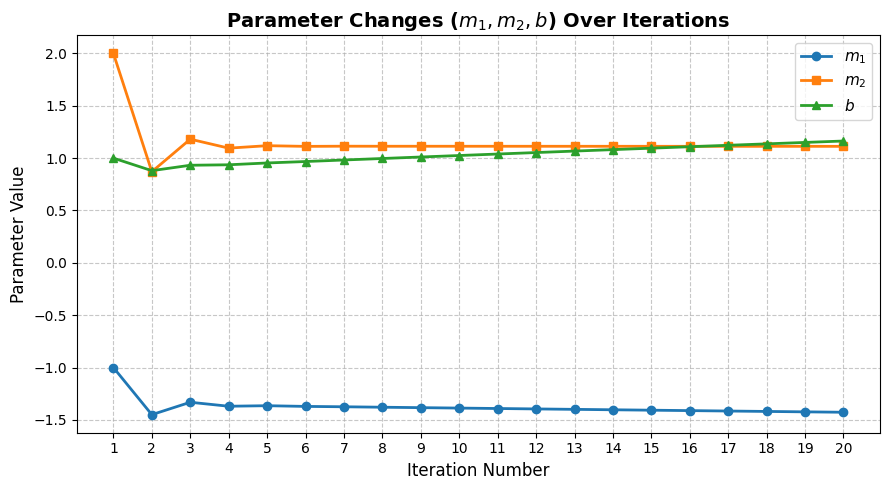

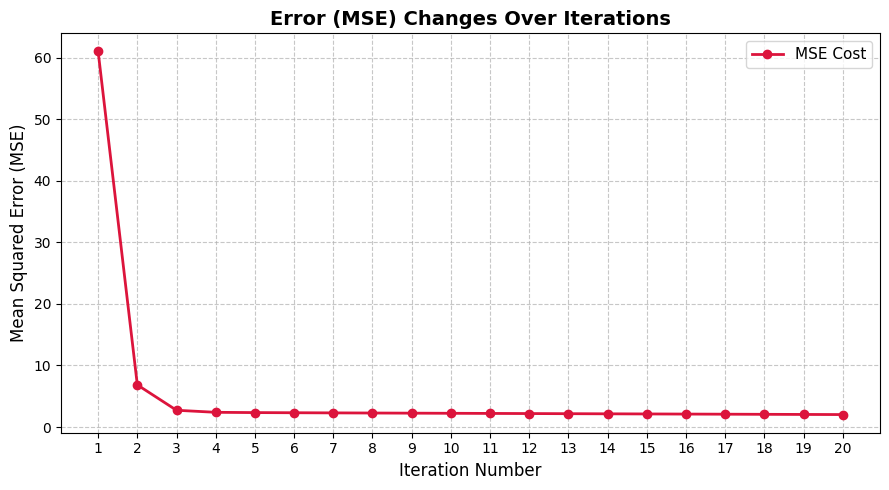

In [8]:
m_history = np.array(m_history)
b_history = np.array(b_history)
iterations_arr = np.arange(1, num_iterations + 1)

# -----------------------------------------------------
# Plot 1: Parameter Changes Over Iterations
# -----------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(iterations_arr, m_history[:, 0], marker='o', linewidth=2, label='$m_1$')
plt.plot(iterations_arr, m_history[:, 1], marker='s', linewidth=2, label='$m_2$')
plt.plot(iterations_arr, b_history, marker='^', linewidth=2, label='$b$')
plt.title('Parameter Changes ($m_1, m_2, b$) Over Iterations', fontsize=14, fontweight='bold')
plt.xlabel('Iteration Number', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
plt.xticks(iterations_arr)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# -----------------------------------------------------
# Plot 2: Error (MSE) Changes Over Iterations
# -----------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(iterations_arr, cost_history, marker='o', color='crimson', linewidth=2, label='MSE Cost')
plt.title('Error (MSE) Changes Over Iterations', fontsize=14, fontweight='bold')
plt.xlabel('Iteration Number', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.xticks(iterations_arr)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()